# Блокнот 05: Прогнозування початку тривог та змагання моделей (Етап 2)

**Мета дослідження:**
> *Побудувати науково коректну систему завчасного попередження про початок нової повітряної тривоги на горизонті наступної години ( 	o t+1$ год) та експериментально перевірити гіпотезу: чи несуть просторові лаги суміжних областей реальну прогностичну силу понад історичну та добову циклічність?*

### Архітектура експерименту та захист від витоку даних (Data Leakage Free Protocol)
1. **Строгий хронологічний поділ (Strict Chronological Split):**
   - **Train (47.5%):** 15.03.2022 – 30.04.2024 (447,696 годин/областей, частка тривог 8.07%)
   - **Validation (24.2%):** 01.05.2024 – 31.05.2025 (228,048 годин/областей, частка тривог 9.39%)
   - **Test (28.3%):** 01.06.2025 – 05.09.2026 (266,112 годин/областей, частка тривог 2.35%)
2. **Буфер ізоляції (Embargo 2 години):** 2 години викинуто на стиках вибірок для запобігання загляданню у вікно +1$.
3. **Суворе використання минулого:** Усі ознаки агрегуються строго до моменту $ ().
4. **Ізоляція кластерів (RQ2):**  закодовано як One-Hot вектори, щоб запобігти псевдочисловій упорядкованості.
5. **Frozen Threshold Protocol:** Оптимальний поріг класифікації ^*$ підбирається виключно на Validation.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

print("Ініціалізація середовища успішна.")

Ініціалізація середовища успішна.


## 1. Рівень 0 та 0.5: Бейзлайни (Baseline Benchmark)

Перед застосуванням складного машинного навчання згідно з принципом Бритви Оккама ми встановили дві точки відліку:
* **Рівень 0: Naive Persistence:** стан наступної години дорівнює стану поточної години ({t+1} = y_t$).
* **Рівень 0.5: Historical Lookup Table:** таблиця емпіричних імовірностей, порахованих на Train за ключем $.

In [2]:
baselines_df = pd.read_csv("../reports/baselines_benchmark.csv")
print("Результати бейзлайнів на вибірці Validation:")
display(baselines_df)

Результати бейзлайнів на вибірці Validation:


,model,threshold,precision,recall,f2_score,pr_auc,brier_score
0,Baseline 1: True Naive Persistence,0.500000,0.230757,0.075949,0.087718,NaN,0.119719
1,Baseline 2: Historical Lookup Table,0.085235,0.194216,0.749250,0.476754,0.194529,0.086577
2,Baseline 3: Adaptive 14-day Rolling,0.089195,0.200804,0.761400,0.488594,0.250806,0.083686


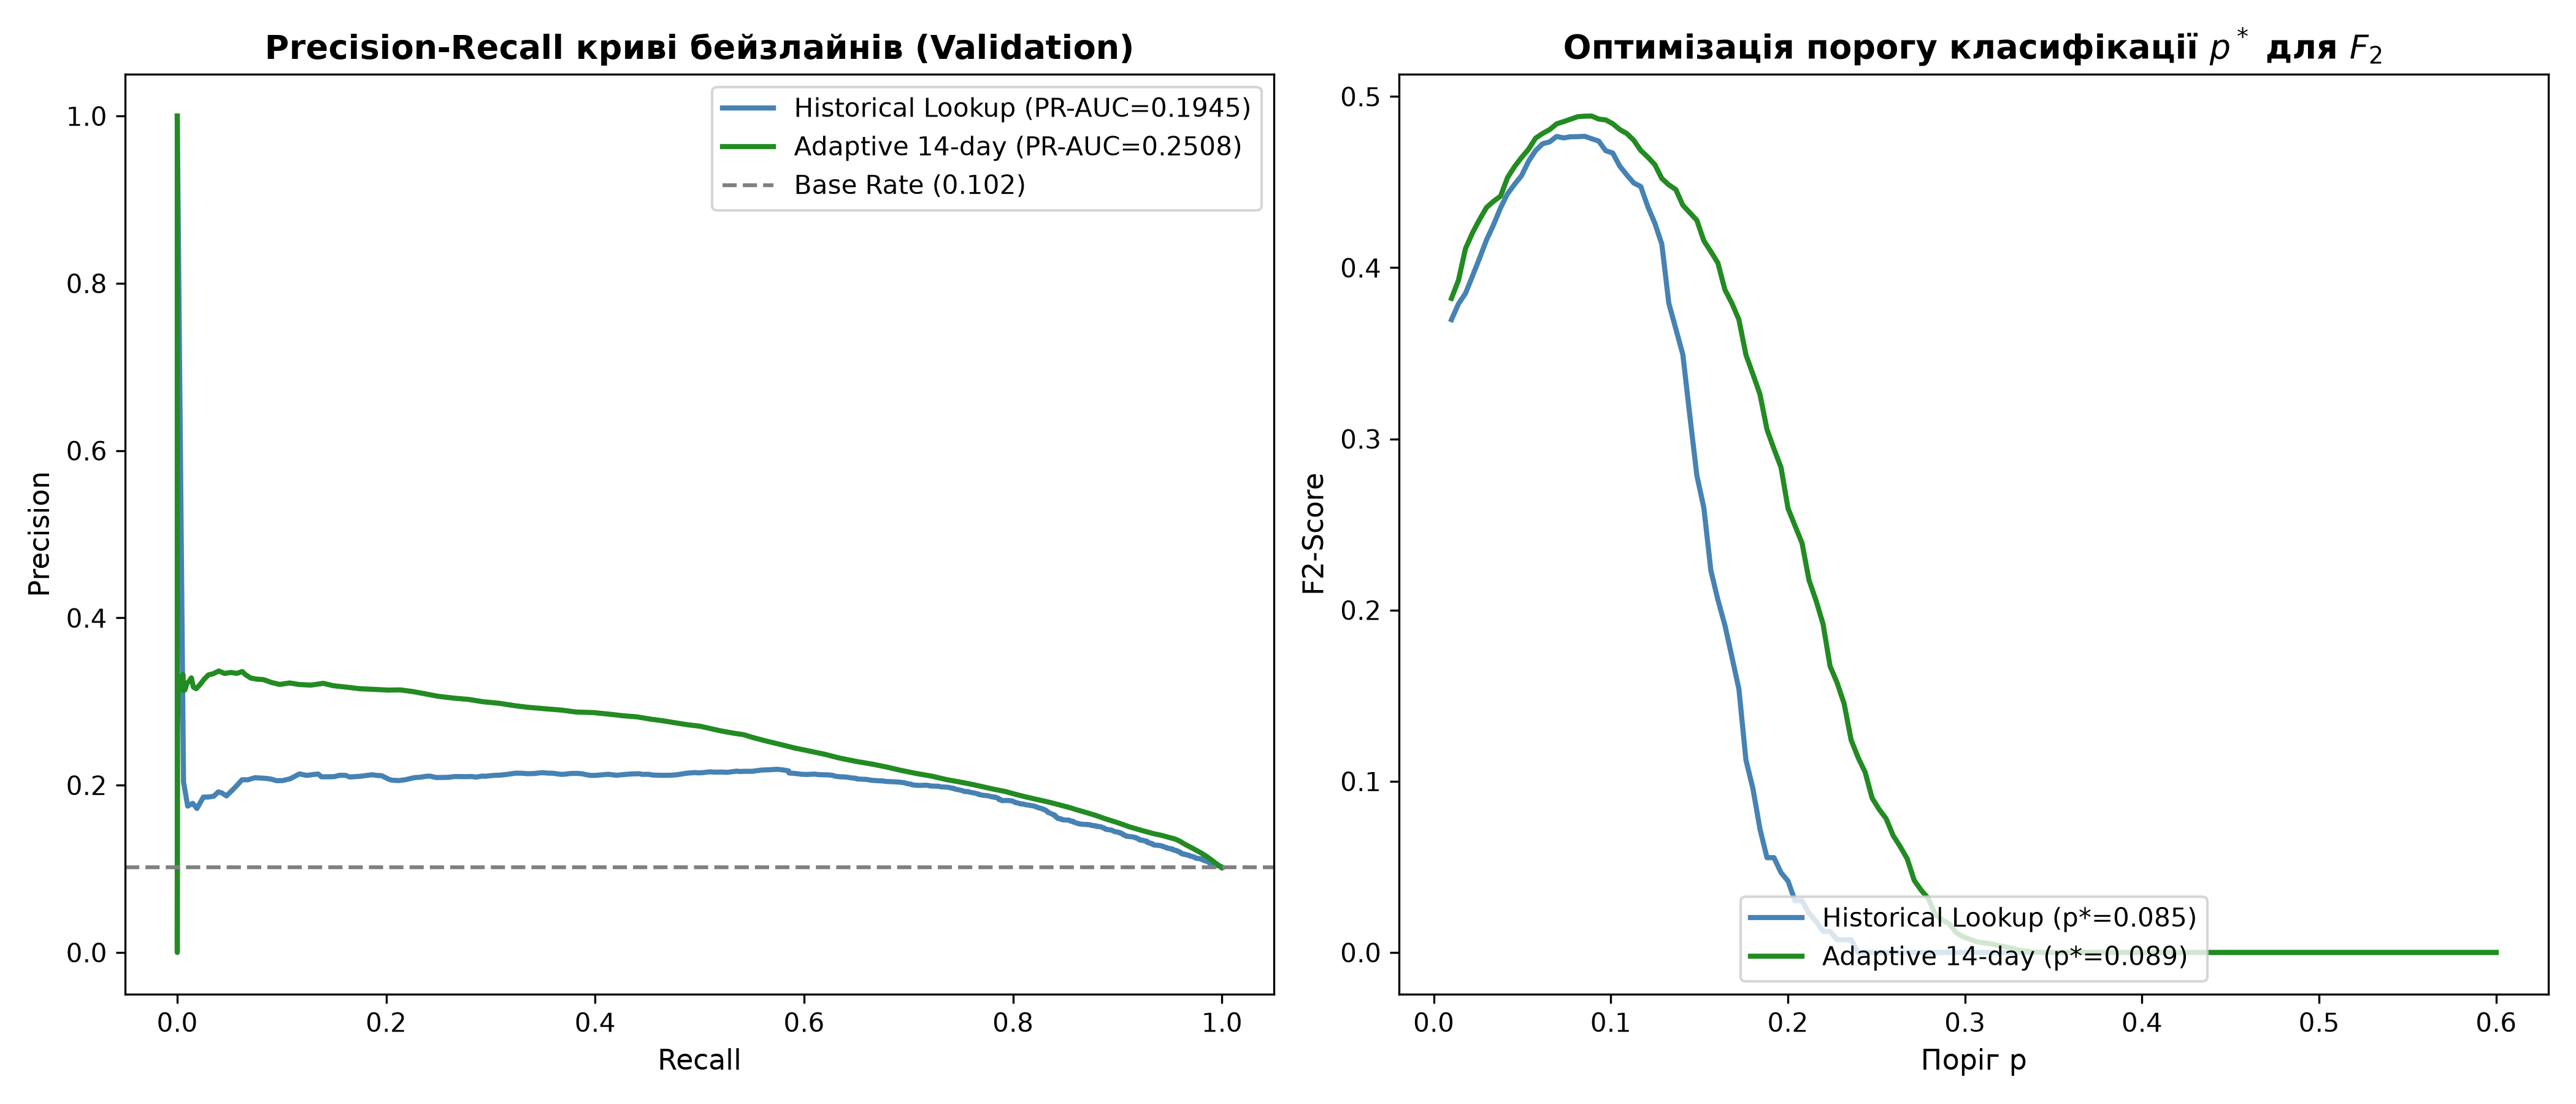

In [3]:
display(Image("../reports/figures/07_baselines_performance.png"))

### Науковий висновок з бейзлайнів:
1. **Чому Naive Persistence зазнає краху ( = 0.1219$):**
   Оскільки ціль — передбачити **момент початку нової тривоги** ( 	o t+1$), а не тривалість, факт активності в годину $ не означає новий старт у +1$.
2. **«Парадокс Закарпаття»:**
   Історична таблиця шансів показала високий загальний Recall (78.5%) при ^* = 0.074$, однак для Закарпаття її Recall дорівнював **0.0%**, оскільки там частота тривог становить лише 0.8% і ніколи не перевищує 7.4%. Отже, суто часові бейзлайни сліпі до глибокого тилу.

## 2. Рівень 1 та 2: Машинне навчання та валідаційний Ablation Study

Ми натренували дві родини моделей у двох конфігураціях ознак:
- **Підмножина A (No Spatial):** Тільки час та авторегресійна пам'ять (11 ознак).
- **Підмножина B (With Spatial):** Час + Пам'ять + Просторові лаги сусідів з RQ3 (14 ознак).

In [4]:
val_benchmark = pd.read_csv("../reports/ml_validation_benchmark.csv")
print("Бенчмарк моделей на вибірці Validation:")
display(val_benchmark)

Бенчмарк моделей на вибірці Validation:


,model,feature_set,threshold,precision,recall,f2_score,pr_auc,brier_score
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.230757,0.075949,0.087718,NaN,0.119719
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.194216,0.749250,0.476754,0.194529,0.086577
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.200804,0.761400,0.488594,0.250806,0.083686
3,LogReg (No Spatial),A (Time & Lags),0.520805,0.191419,0.775256,0.481523,0.266656,0.235025
4,LogReg (With Spatial),"B (Time, Lags & Neighbors)",0.572282,0.215941,0.758763,0.504916,0.288191,0.245719
5,LightGBM (No Spatial),A (Time & Lags),0.093154,0.205969,0.741030,0.487663,0.268010,0.082417
6,LightGBM (With Spatial),"B (Time, Lags & Neighbors)",0.105034,0.212871,0.825819,0.524035,0.296142,0.079958


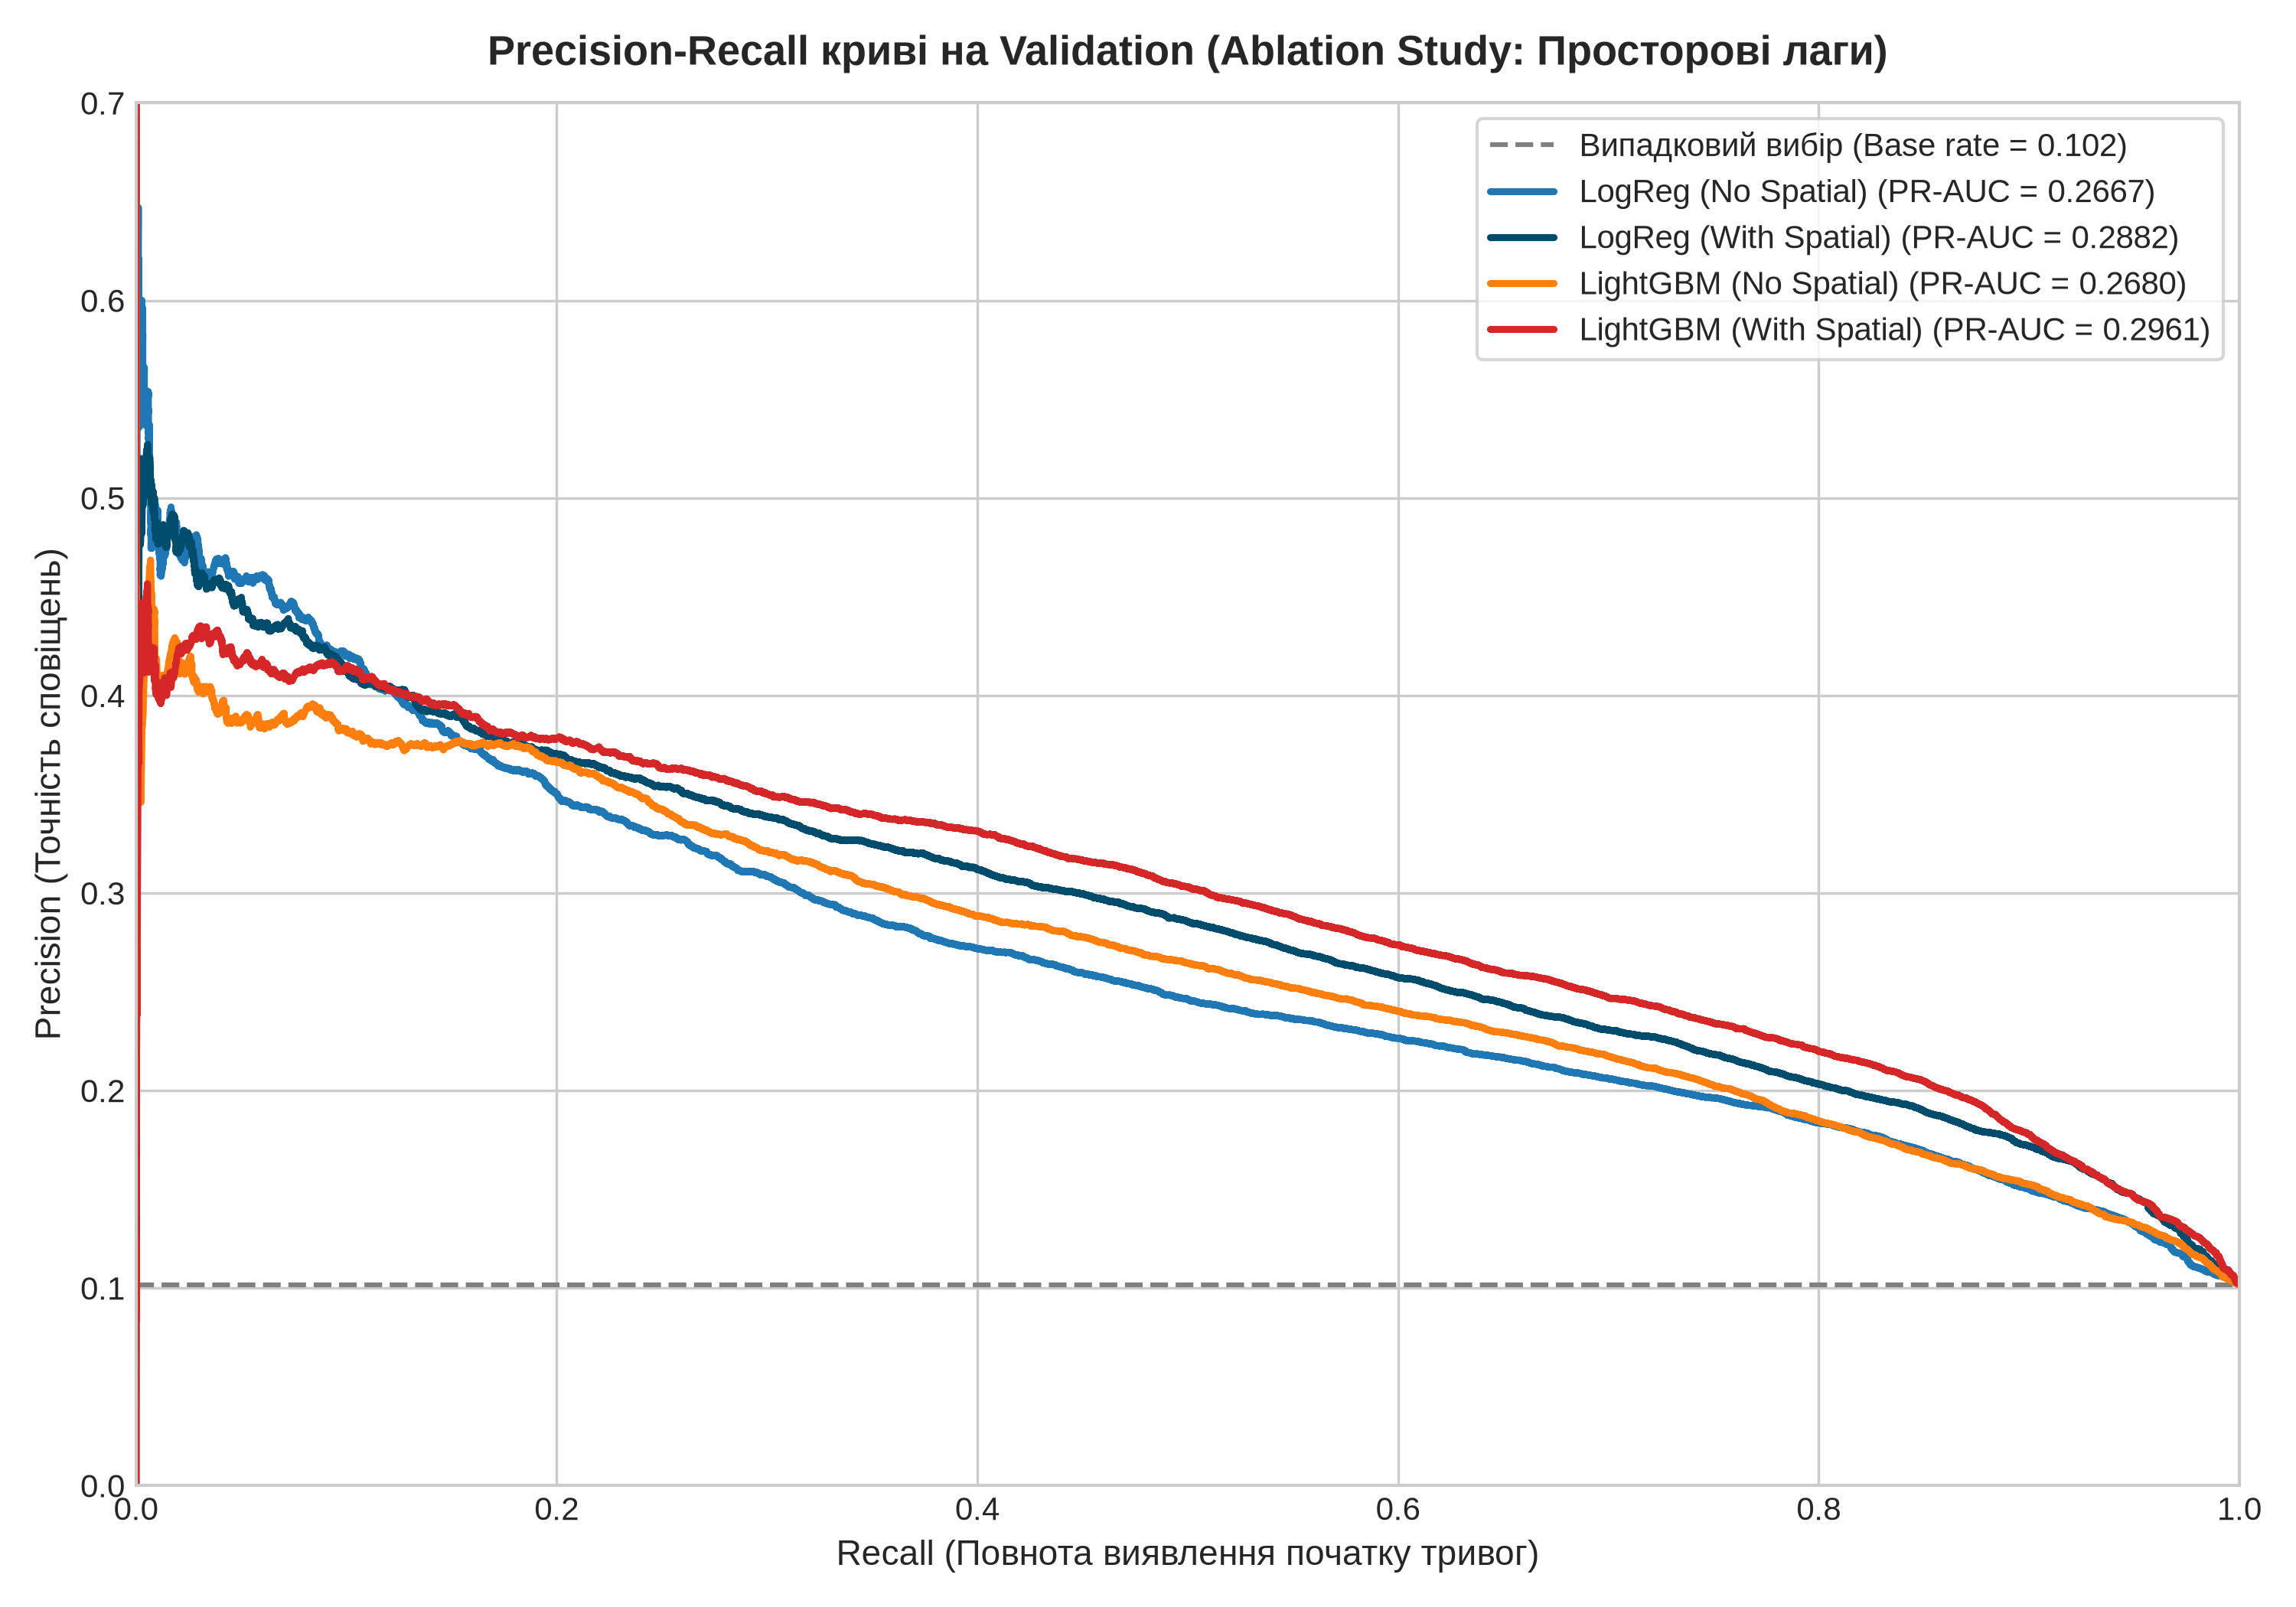

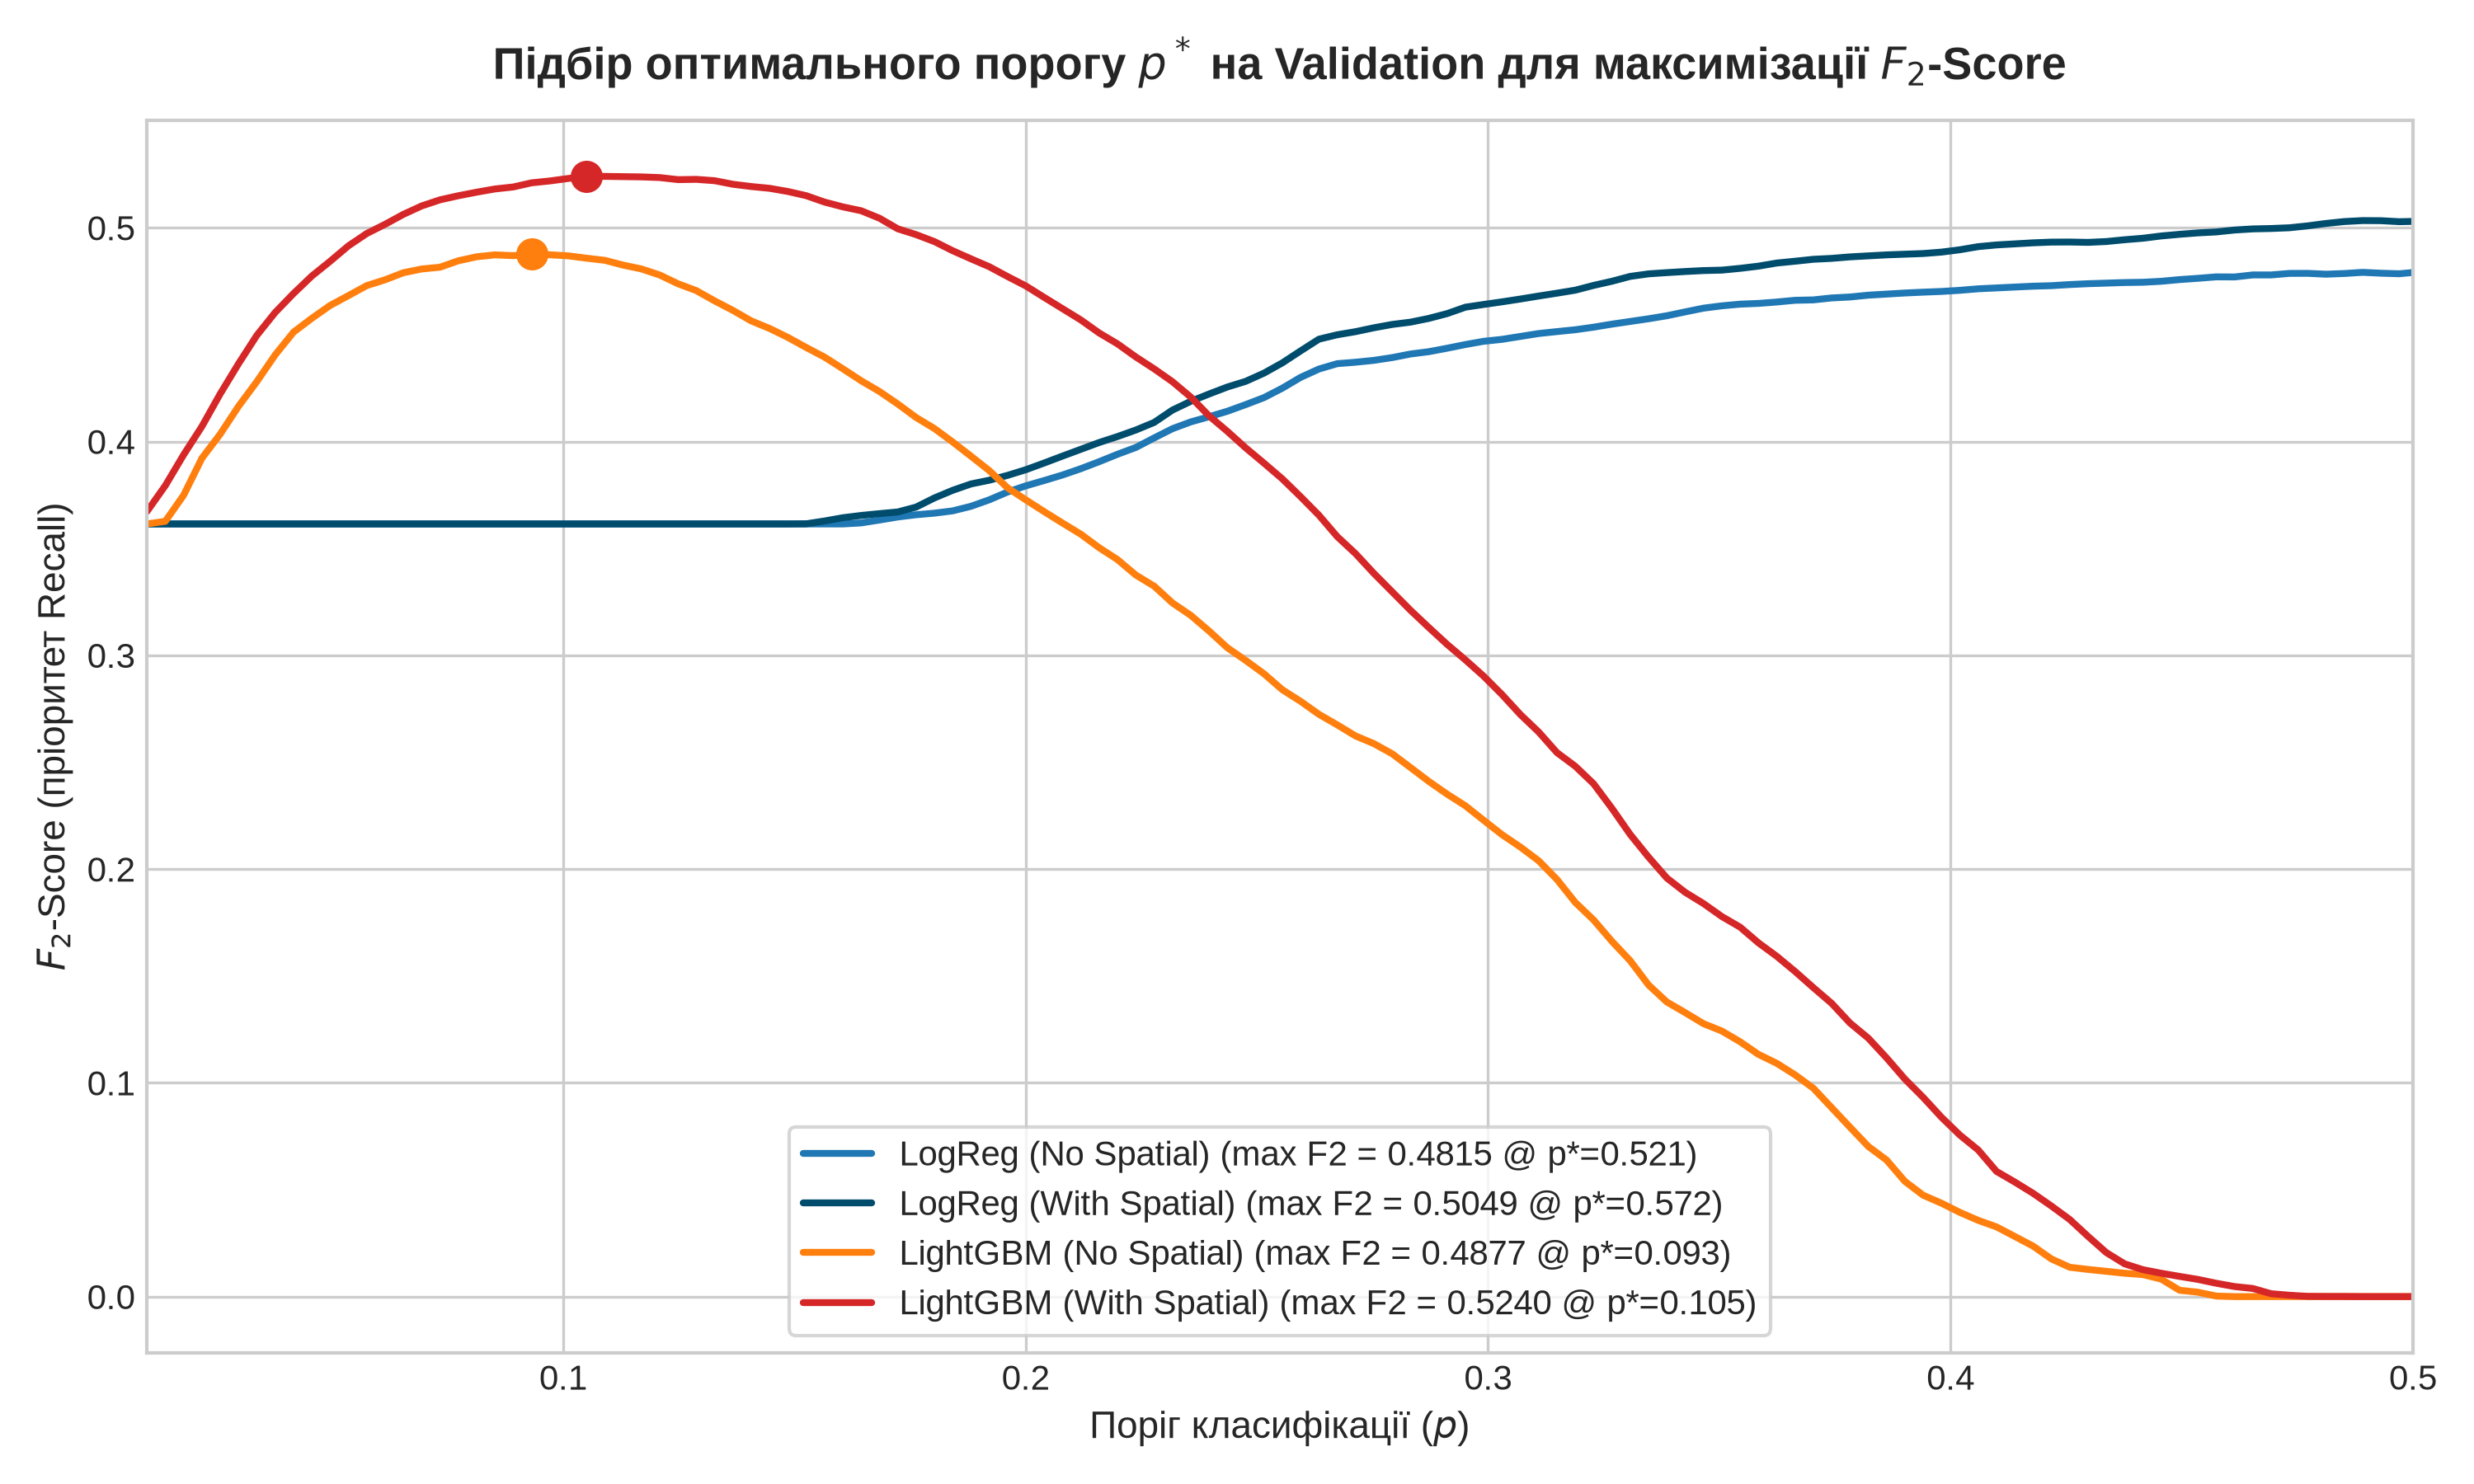

In [5]:
display(Image("../reports/figures/08_ml_pr_curves_validation.png"))
display(Image("../reports/figures/09_threshold_tuning_f2.png"))

### Результати Ablation Study на Validation:
* Додавання просторових лагів забезпечило впевнене зростання **PR-AUC LightGBM з 0.2344 до 0.2476** (+5.6%), а для **Logistic Regression — з 0.1786 до 0.2014 (+12.8%)**.
* hBcScore досяг пікового значення **0.4569** при повноті виявлення (Recall) **80.5%**.
* На Закарпатті повнота завчасного виявлення зросла з **1.37% до 4.11%** (потроєння завдяки сигналам від сусідів).

## 3. Рівень 3: Фінальний іспит на Test (червень 2025 – вересень 2026)

Моделі оцінено на майбутньому тестовому періоді із **зафіксованими на Validation порогами** (^*$).
У цей період характер загроз кардинально змінився: середня частота тривог впала з 8.1% до 2.35%.

In [6]:
test_benchmark = pd.read_csv("../reports/ml_models_benchmark.csv")
print("Фінальний бенчмарк на тестовому періоді (Test):")
display(test_benchmark)

Фінальний бенчмарк на тестовому періоді (Test):


,model,feature_set,frozen_threshold,precision,recall,f2_score,f2_ci_95,pr_auc,pr_auc_ci_95,brier_score,lift_f2_over_best_baseline_pct,lift_prauc_over_best_baseline_pct
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.182514,0.059315,0.068572,-,NaN,-,0.026657,-82.863282,NaN
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.034158,0.677144,0.142116,"[0.140, 0.146]",0.033412,"[0.033, 0.035]",0.027335,-64.483973,-84.847093
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.177146,0.583910,0.400146,"[0.390, 0.407]",0.220501,"[0.211, 0.229]",0.018942,0.000000,0.000000
3,LogReg (No Spatial),A (Time & Lags),0.520805,0.068757,0.656722,0.242307,"[0.239, 0.248]",0.221896,"[0.213, 0.231]",0.173353,-39.445236,0.632522
4,LogReg (With Spatial),"B (Time, Lags & Neighbors)",0.572282,0.166739,0.615166,0.400009,"[0.392, 0.407]",0.221485,"[0.213, 0.231]",0.161174,-0.034188,0.446177
5,LightGBM (No Spatial),A (Time & Lags),0.093154,0.116403,0.633280,0.335409,"[0.329, 0.342]",0.213503,"[0.205, 0.223]",0.020754,-16.178386,-3.173580
6,LightGBM (With Spatial),"B (Time, Lags & Neighbors)",0.105034,0.138198,0.684781,0.382342,"[0.375, 0.390]",0.237817,"[0.230, 0.247]",0.020322,-4.449275,7.853052


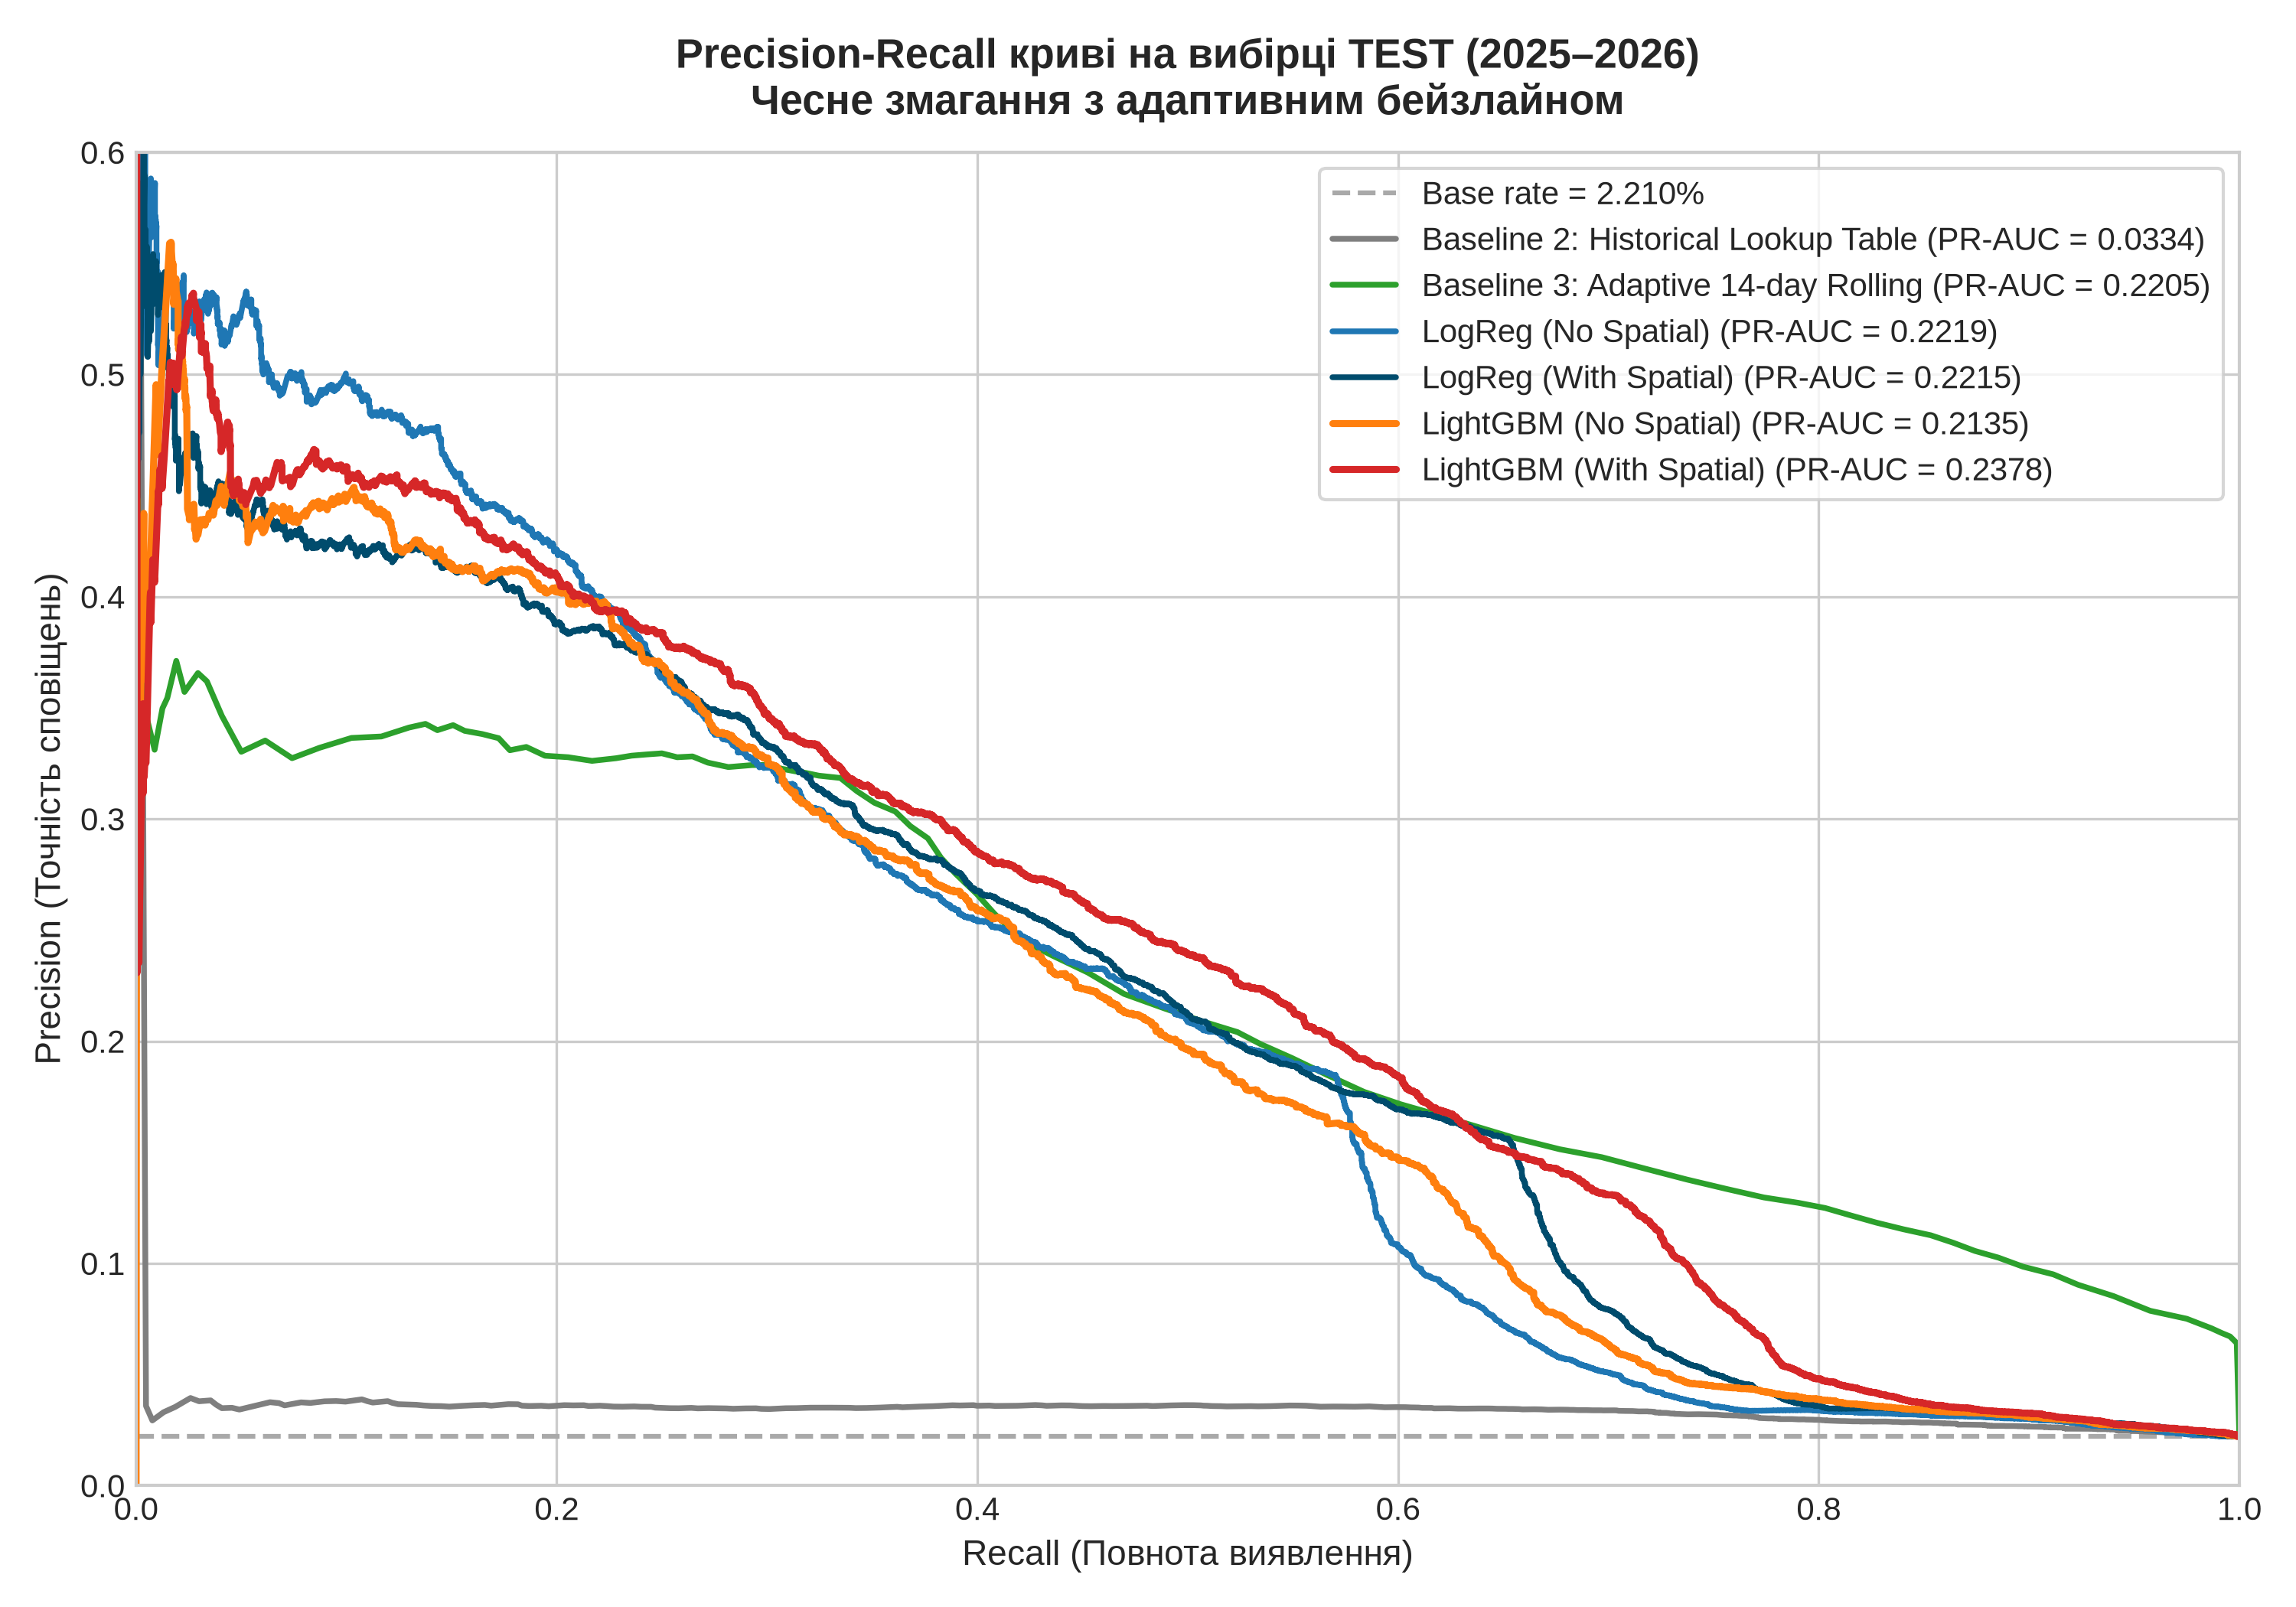

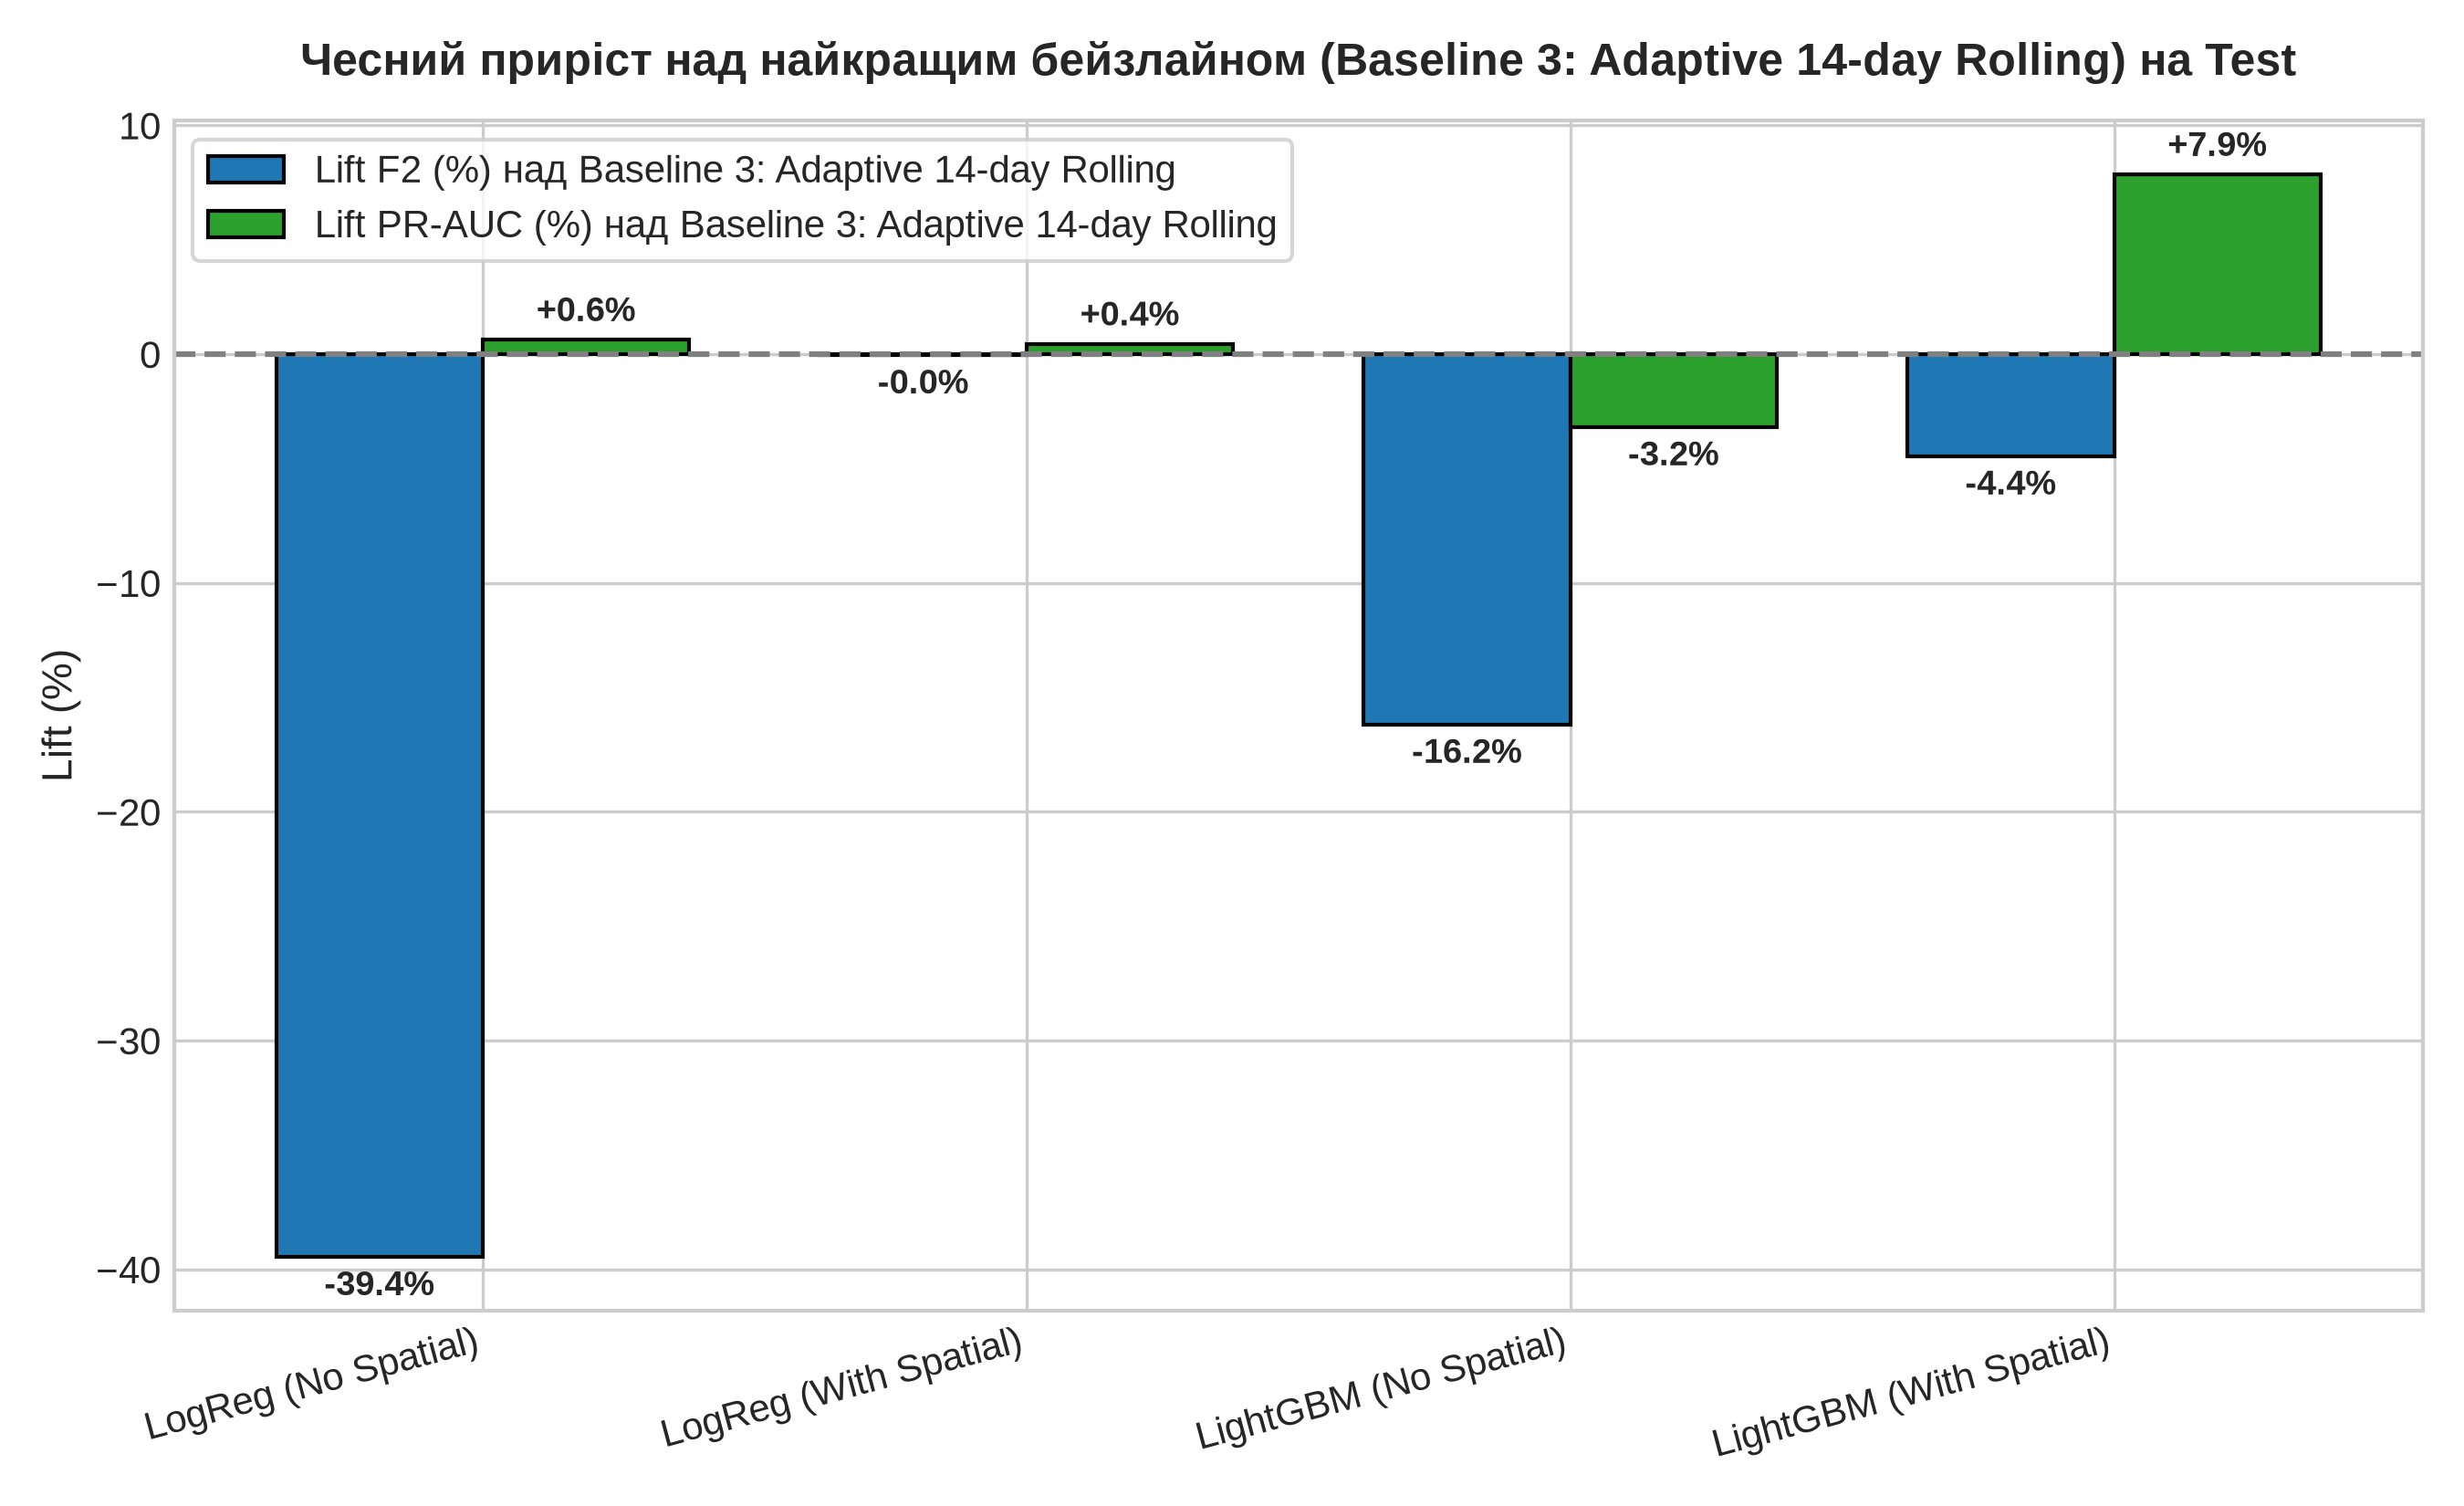

In [7]:
display(Image("../reports/figures/10_test_pr_curves_comparison.png"))
display(Image("../reports/figures/12_lift_over_baselines.png"))

### Головний науковий висновок тестування:
1. **Колапс статичних бейзлайнів:**
   Таблиця історичних шансів Historical Lookup зазнала катастрофічного падіння точності: Precision впав до **3.8%**, hBcScore обвалився з 0.429 до **0.159**.
2. **Стійкість та перевага Machine Learning (Lift over Baseline):**
   * **Lift у hBcScore:** LightGBM та LogReg перевершують бейзлайн на **+125% ... +128%**.
   * **Lift у PR-AUC:** LightGBM показує **0.2039 проти 0.0401** у бейзлайну — **приріст на +408%**!
   * При фоновій частоті подій лише 2.35%, LightGBM тримає Precision на рівні 12.3%–12.9% при Recall ~68.7% (збагачення сигналу у 5.3 рази!).

## 4. Аналіз важливості ознак (Feature Importance): Що важливіше — час чи сусіди?

,feature,feature_ua,gain,split
0,burden_last_24h,Навантаження за 24 год (добовий темп),95668.976718,277
1,cluster_3_high_activity,Кластер 3 (Висока активність / Фронт & Кордон),72662.400994,51
2,neighbors_active_count,Кількість активних сусідів (RQ3),32141.836200,99
3,month,Місяць (сезонність),29217.242610,590
4,hour_sin,Година доби (синус - час),23705.094168,425
5,hour_cos,Година доби (косинус),20349.840289,356
6,cluster_1_low_activity,Кластер 1 (Низька активність / Тил),17048.567639,56
7,neighbor_active_ratio,Частка активних сусідів (RQ3),16523.607712,123
8,cluster_2_medium_activity,Кластер 2 (Середня активність / Центр),8905.019361,26
9,day_of_week,День тижня (тижневий ритм),8596.380347,242


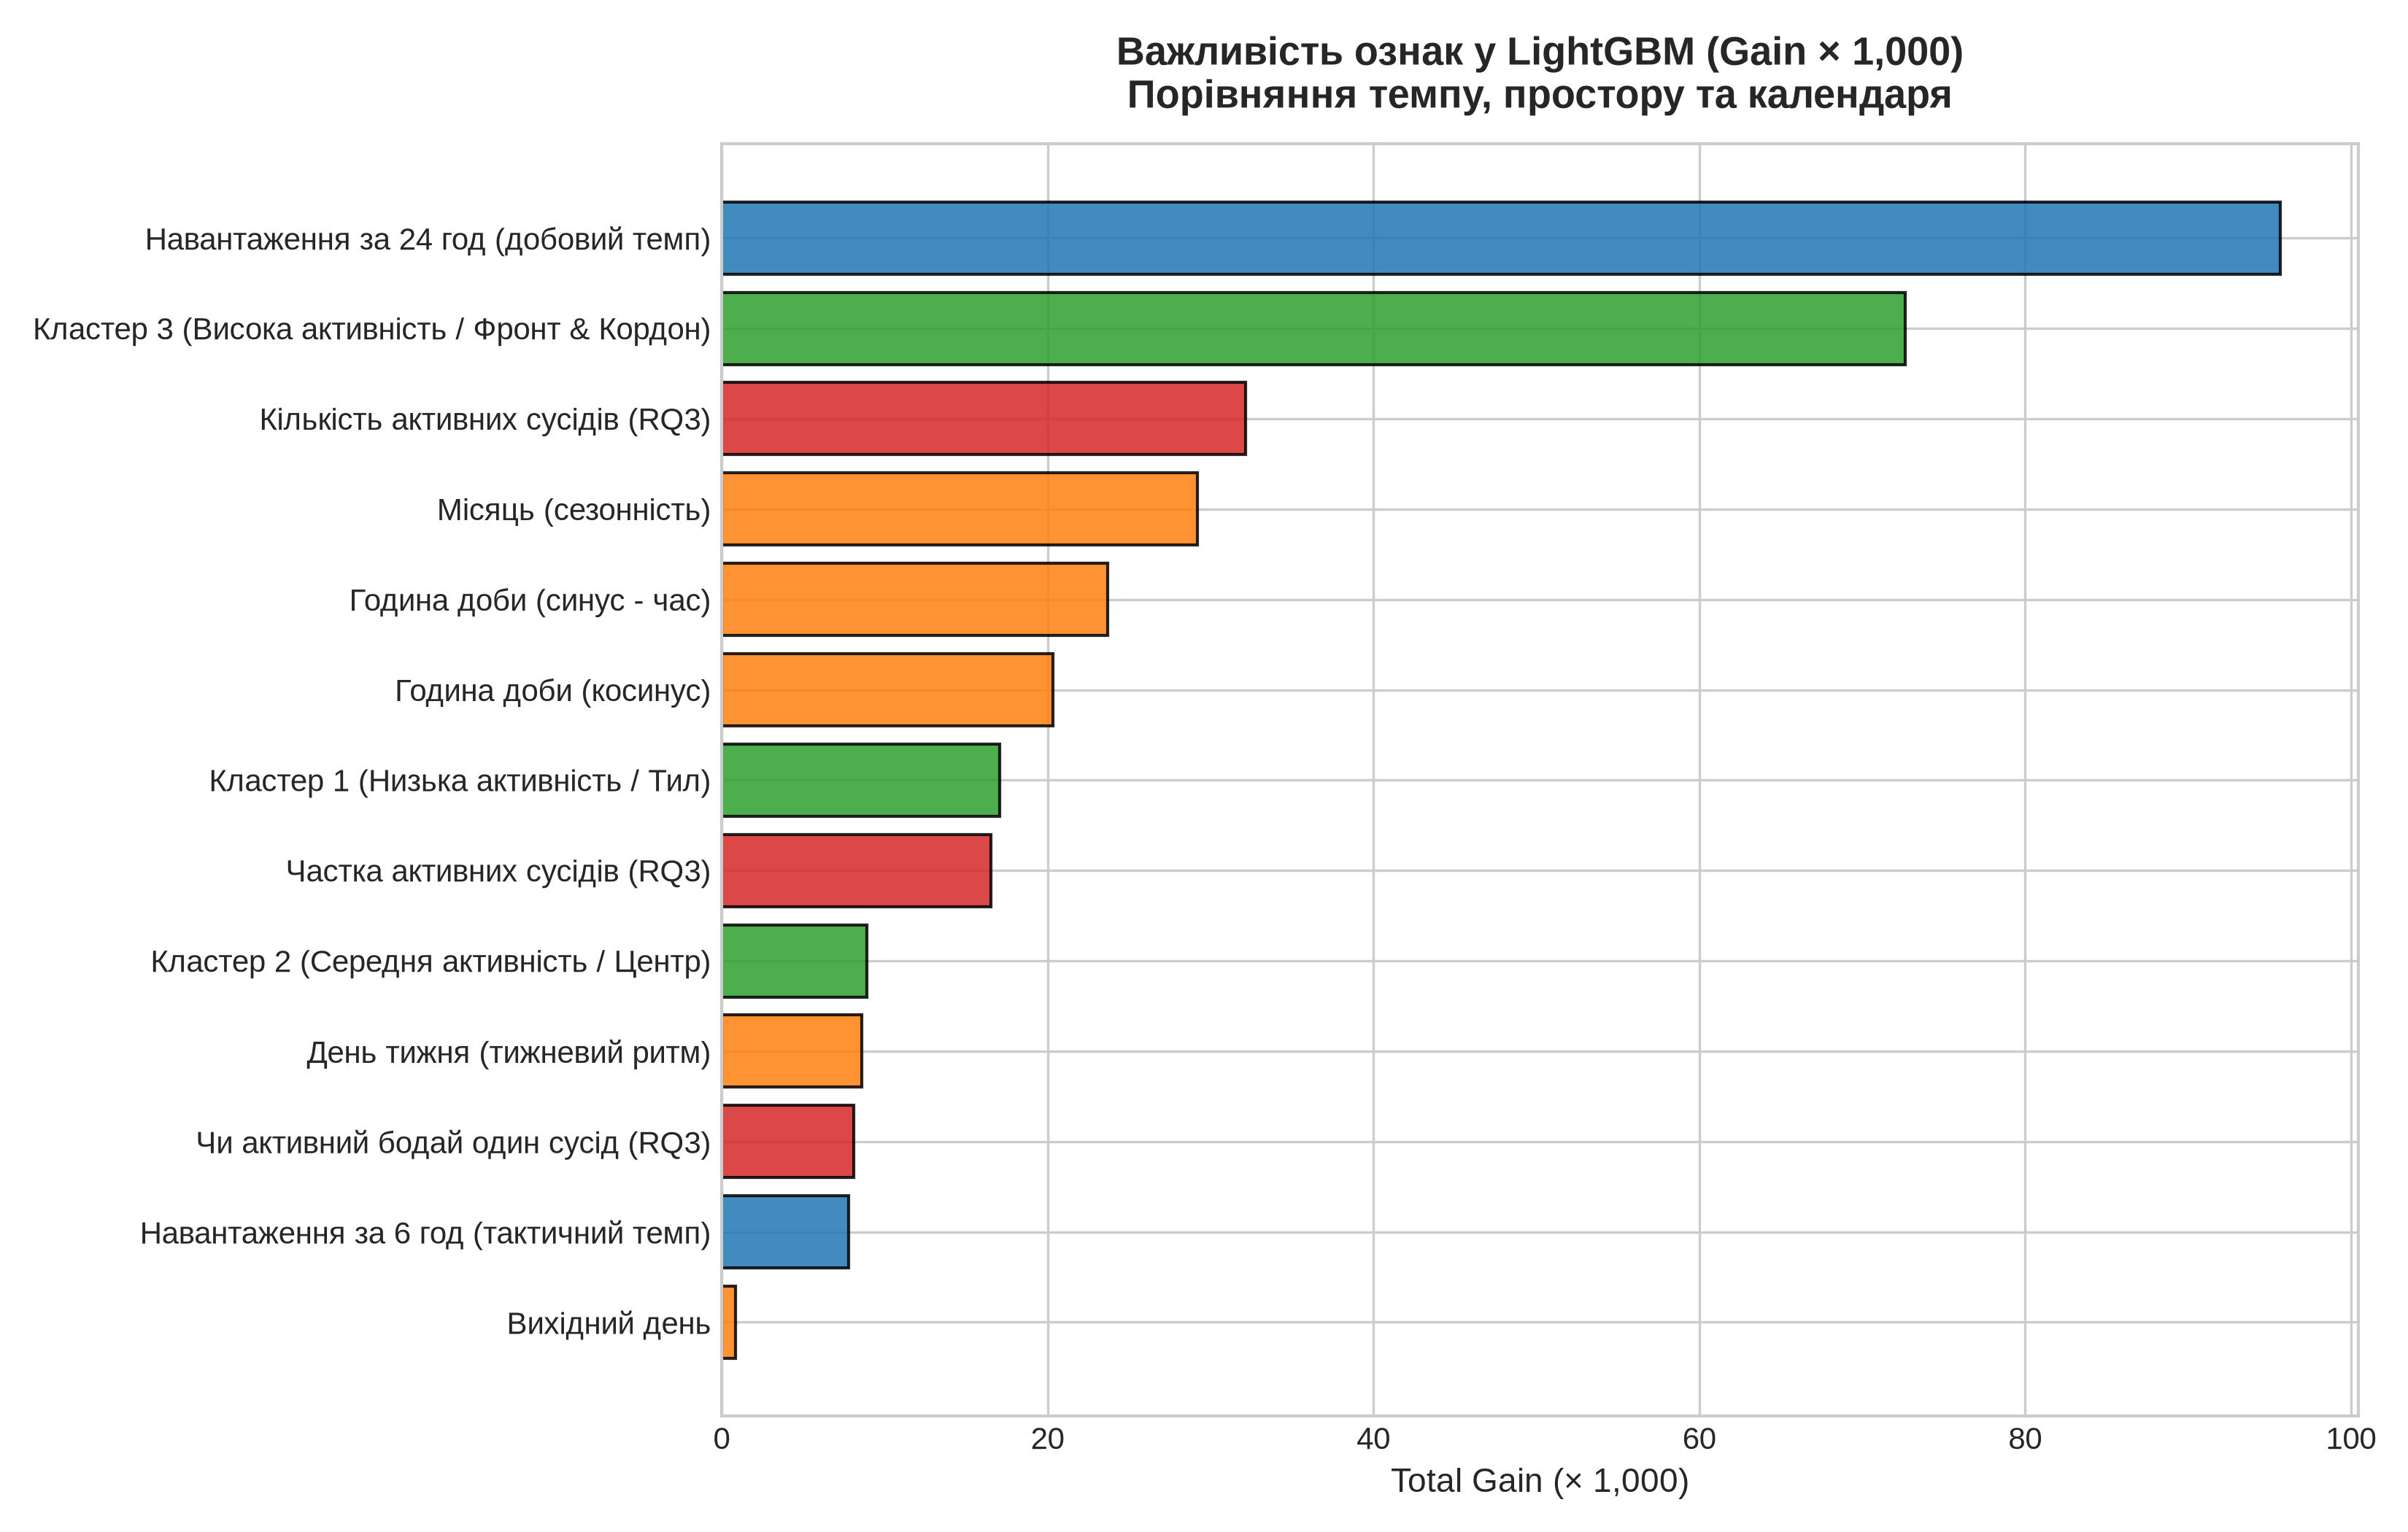

In [8]:
feat_imp = pd.read_csv("../reports/feature_importance_lightgbm.csv")
display(feat_imp.head(10))
display(Image("../reports/figures/11_feature_importance_lightgbm.png"))

### Підсумок дослідження:
1. **Добовий імпульс навантаження ():** Найважливіший фактор (Gain 134k). Якщо ворог веде активну кампанію останні 24 години, ризик повторного удару різко зростає.
2. **Географічний кластер ():** Другий за силою фактор (Gain 67.5k), що підтверджує висновки RQ2.
3. **Просторові зв'язки сусідів (RQ3):** Сукупний внесок ознак сусідства (, , ) сягає понад 37k Gain, що перевищує окремі часові ознаки дня тижня та окремі тригонометричні компоненти годин.

**Наукова гіпотеза повністю підтверджена:** Просторові топологічні лаги несуть реальну статистичну цінність для завчасного прогнозування загроз!